# Curve bootstrap and fit

Research question: Does the curve reprice its idealised inputs, and what does fitting change?

Inputs: frozen Treasury 2024–2025 CSVs. Rates are decimals, prices per 100 face. Release 1.0.0. No live signal.

In [1]:
import sys,json
from pathlib import Path
from datetime import date
import numpy as np
R=Path.cwd()
if R.name=='notebooks':R=R.parent
sys.path.insert(0,str(R/'src'));sys.path.insert(0,str(R/'scripts'))
from curve_lab.data import load_history
from curve_lab.bonds import Bond
from curve_lab.curves import bootstrap,par_rate,TENORS,KEYS,fit_nelson_siegel
from curve_lab.risk import bond_risk,hedge,carry_bridge
from curve_lab.forecast import predict,evaluate
from review_display import table,figure
if 'display_bundle' not in globals():
    from IPython.display import display
    def display_bundle(bundle):display(bundle,raw=True)
D=json.loads((R/'artifacts/release/research.json').read_text());rows,receipts=load_history(R)
print('Run',D['run_id'],'| source through',D['as_of'],'| hypothetical bond valuations')


Run p4-662f58a64e8e | source through 2025-12-31 | hypothetical bond valuations


## Rebuild the educational bootstrap

In [2]:
c=bootstrap(rows[-1]['par']);res=[(par_rate(c,t)-p)*10000 for t,p in zip(TENORS,rows[-1]['par'])];display_bundle(table(['Tenor','Input par','Repriced par','Residual bp'],[[t,p,par_rate(c,t),r] for t,p,r in zip(TENORS,rows[-1]['par'],res)]));assert max(abs(x) for x in res)<1e-8

Tenor,Input par,Repriced par,Residual bp
0.5,0.0359,0.0359,-1.8735014e-12
1,0.0348,0.0348,9.0205621e-13
2,0.0347,0.0347,-6.9388939e-14
3,0.0355,0.0355,-6.9388939e-14
5,0.0373,0.0373,1.3877788e-13
7,0.0394,0.0394,6.9388939e-14
10,0.0418,0.0418,-2.0816682e-13
20,0.0479,0.0479,0
30,0.0484,0.0484,6.9388939e-14


## Fit the parametric challenger

Parameter,Value
Level,0.055951793
Slope,-0.019633077
Curvature,-0.032899085
Tau,2.8089916


Par RMSE bp: 3.619541091641144


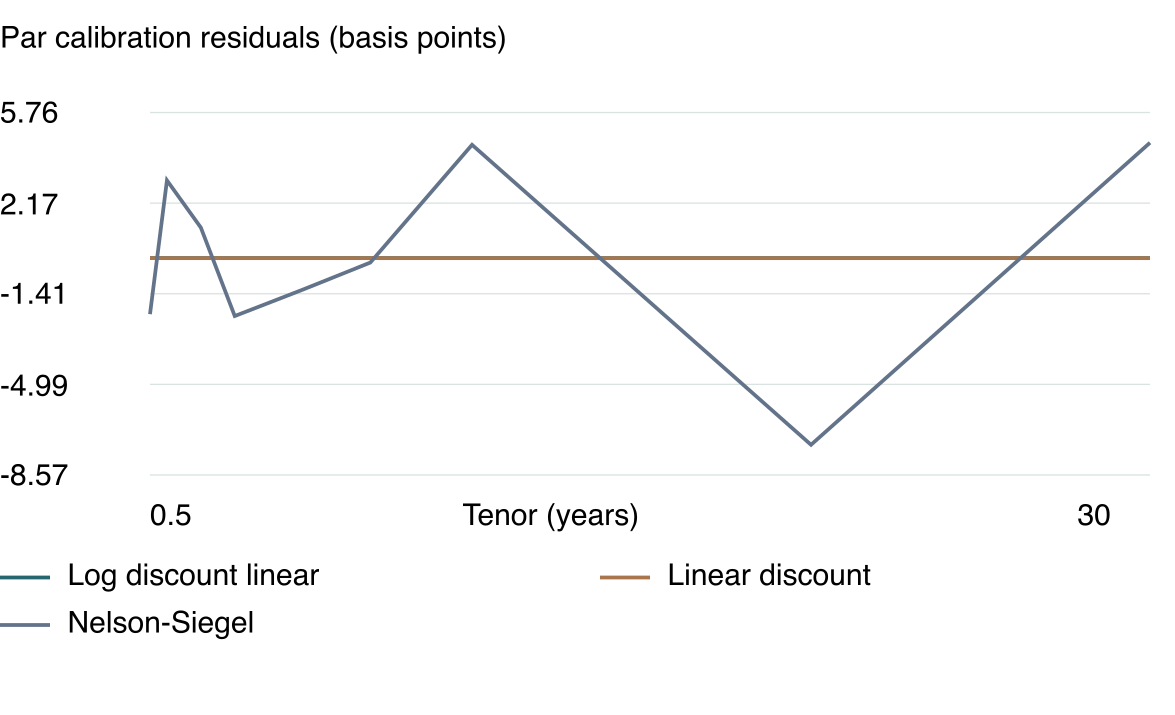

In [3]:
ns,fit=fit_nelson_siegel(np.array(rows[-1]['par']));display_bundle(table(['Parameter','Value'],zip(['Level','Slope','Curvature','Tau'],fit['parameters'])));print('Par RMSE bp:',fit['rmse_bp']);display_bundle(figure('residuals'))

## Bootstrap three periods by hand

In [4]:
coupons=[.04,.042,.044];dd=[]
for cp in coupons:dd.append((1-cp/2*sum(dd))/(1+cp/2))
display_bundle(table(['Half-year period','Coupon','Discount'],[[j+1,cp,d] for j,(cp,d) in enumerate(zip(coupons,dd))]));assert abs(dd[0]-1/1.02)<1e-12

Half-year period,Coupon,Discount
1,0.04,0.98039216
2,0.042,0.95926715
3,0.044,0.93671966


## Interpretation

Exact idealised repricing is a calibration identity. Linear and log-discount interpolation share nodes but differ off grid. The Nelson-Siegel residual is retained; no fit improvement is treated as security-price validation.

Canonical evidence: `artifacts/release/research.json`; source receipts: `data/manifests/sources.json`.